# Business and Data Understanding

Este notebook reproduz a análise de risco de crédito usando as funções refatoradas em `default_detector.analysis` e `default_detector.plots`.

In [1]:
from pathlib import Path

import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
sns.set_palette("rocket")

project_root = Path.cwd().resolve()
if not (project_root / "data" / "raw" / "credit_risk_dataset.csv").exists():
    project_root = project_root.parent

from default_detector.analysis import (
    build_analysis_payload,
    load_credit_dataset,
    save_analysis_payload,
    train_and_evaluate_models,
    validate_required_columns,
)
from default_detector.plots import (
    plot_categorical_rates,
    plot_numeric_by_target,
    plot_numeric_correlation,
    plot_permutation_importance,
    plot_roc_curves,
    plot_target_distribution,
)

df = load_credit_dataset(project_root)
missing_columns = validate_required_columns(df)
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

df.head()

,idade,renda,tipo de propriedade da residência,tempo de emprego,finalidade do empréstimo,classificação do empréstimo,valor do empréstimo,taxa de juros do empréstimo,status do empréstimo,Percentual da renda comprometido com o empréstimo,histórico de inadimplência no cadastro de crédito,Tempo de histórico de crédito
0,22,59000,Aluguel,123.0,Pessoal,D,35000,16.02,1,0.59,Sim,3
1,21,9600,Própria,5.0,Educação,B,1000,11.14,0,0.10,Não,2
2,25,9600,Financiada,1.0,Médico,C,5500,12.87,1,0.57,Não,3
3,23,65500,Aluguel,4.0,Médico,C,35000,15.23,1,0.53,Não,2
4,24,54400,Aluguel,8.0,Médico,C,35000,14.27,1,0.55,Sim,4


In [2]:
# payload = build_analysis_payload(df, project_root)
# save_analysis_payload(payload, project_root=project_root)

# payload["quality"]

In [3]:
payload["class_distribution"]

NameError: name 'payload' is not defined

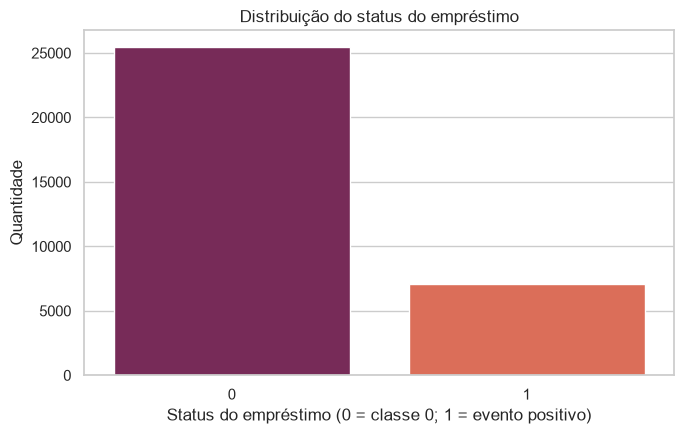

WindowsPath('C:/PROJETOS NO GIT/IMPACTA - Data Avengers/figures/01_target_distribution.png')

In [ ]:
plot_target_distribution(df, output_dir=project_root / "figures")

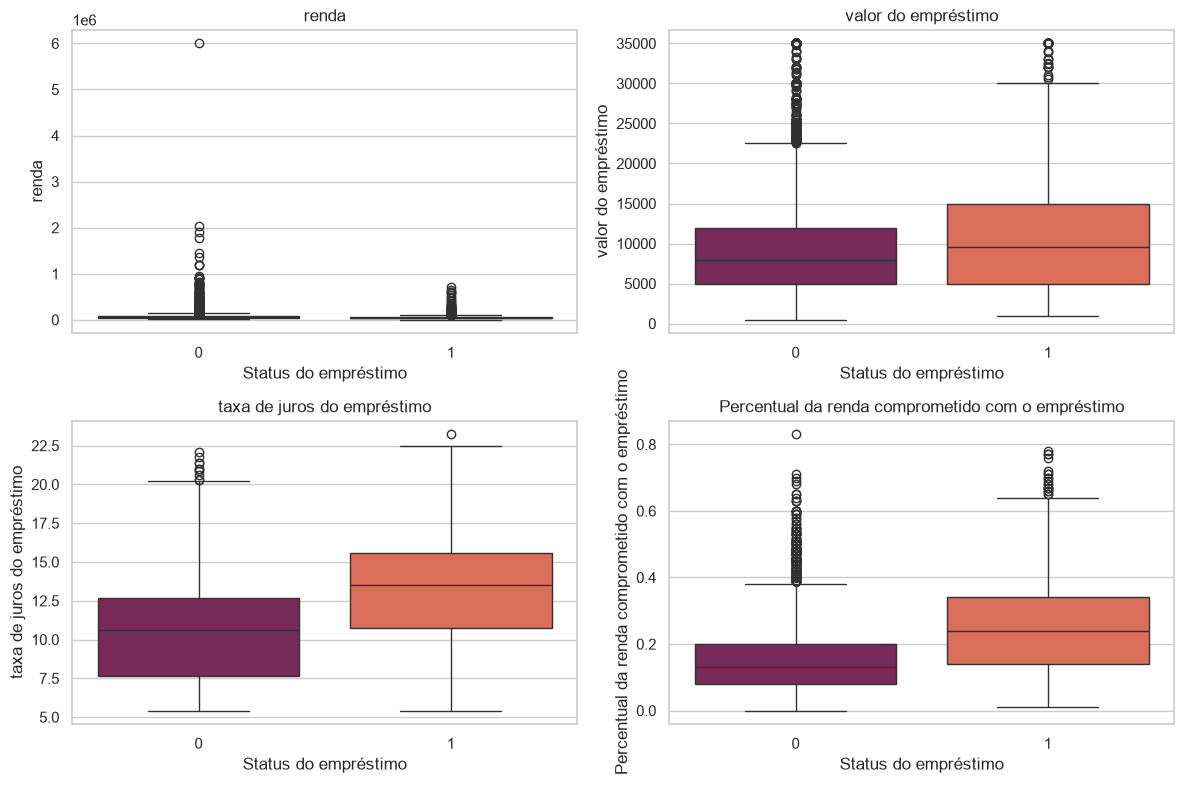

WindowsPath('C:/PROJETOS NO GIT/IMPACTA - Data Avengers/figures/02_numeric_by_target.png')

In [ ]:
plot_numeric_by_target(df, output_dir=project_root / "figures")

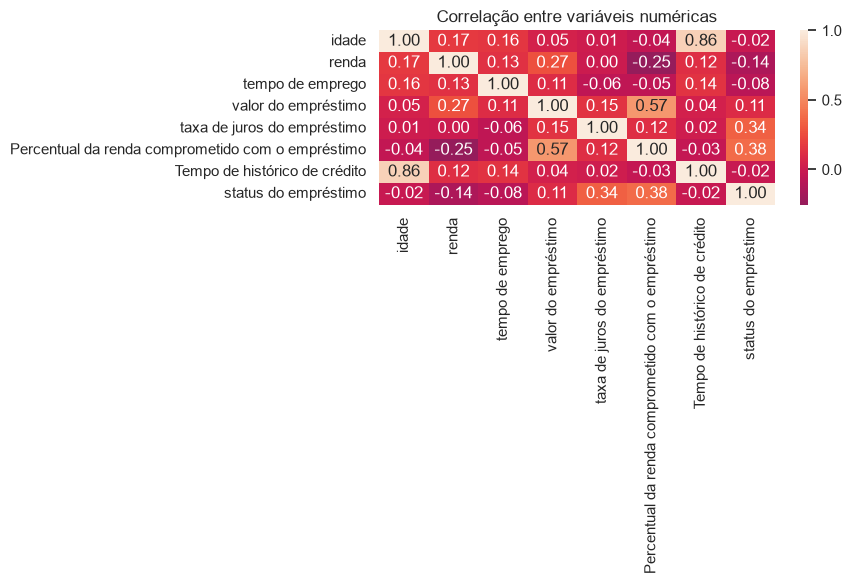

WindowsPath('C:/PROJETOS NO GIT/IMPACTA - Data Avengers/figures/03_correlation.png')

In [ ]:
plot_numeric_correlation(df, output_dir=project_root / "figures")

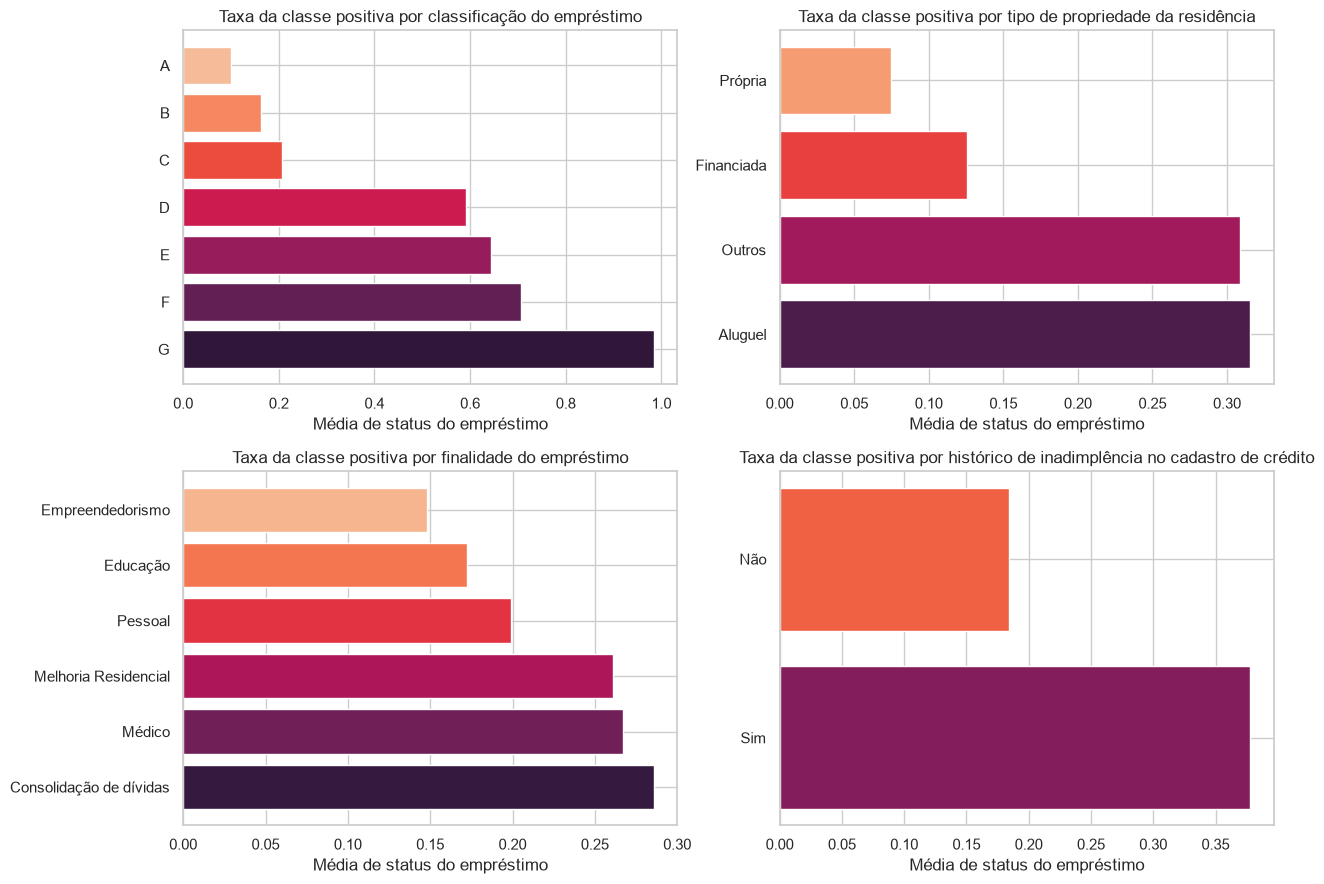

WindowsPath('C:/PROJETOS NO GIT/IMPACTA - Data Avengers/figures/04_categorical_payment_rates.png')

In [4]:
plot_categorical_rates(df, output_dir=project_root / "figures")

In [5]:
modeling = train_and_evaluate_models(df)
modeling["model_results"]

{'Regressão Logística': {'accuracy': 0.8136,
  'precision': 0.5515,
  'recall': 0.7799,
  'f1': 0.6461,
  'roc_auc': 0.8712,
  'average_precision': 0.7203,
  'confusion_matrix': [[4193, 902], [313, 1109]],
  'classification_report': {'0': {'precision': 0.9305370616955171,
    'recall': 0.822963689892051,
    'f1-score': 0.8734506822206021,
    'support': 5095.0},
   '1': {'precision': 0.5514669318746892,
    'recall': 0.779887482419128,
    'f1-score': 0.6460821438974658,
    'support': 1422.0},
   'accuracy': 0.8135645235537824,
   'macro avg': {'precision': 0.7410019967851031,
    'recall': 0.8014255861555895,
    'f1-score': 0.7597664130590339,
    'support': 6517.0},
   'weighted avg': {'precision': 0.8478245061323411,
    'recall': 0.8135645235537824,
    'f1-score': 0.8238391951106587,
    'support': 6517.0}}},
 'Random Forest': {'accuracy': 0.9193,
  'precision': 0.859,
  'recall': 0.7539,
  'f1': 0.803,
  'roc_auc': 0.9316,
  'average_precision': 0.8825,
  'confusion_matrix': [

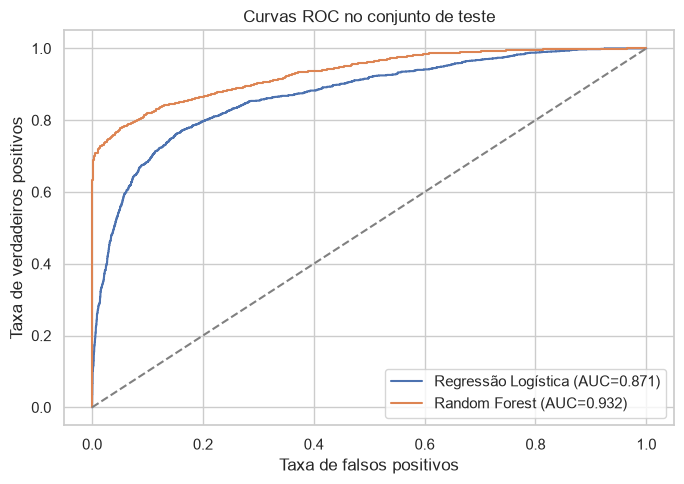

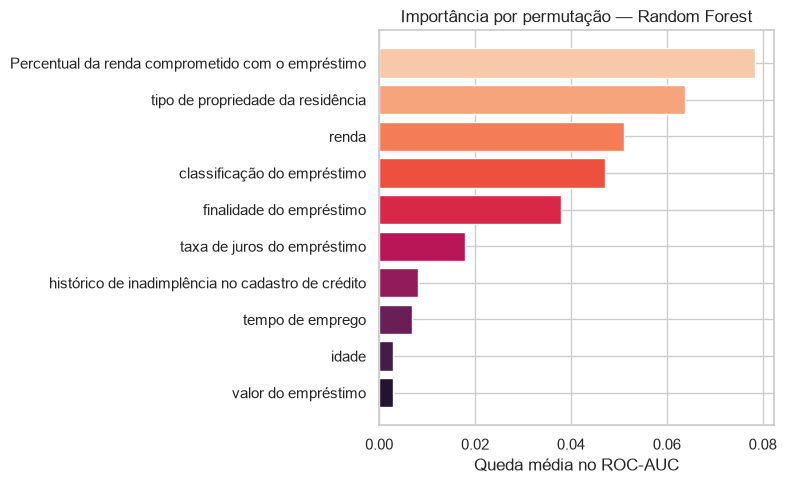

Figuras salvas em: C:\PROJETOS NO GIT\IMPACTA - Data Avengers\figures
Relatório salvo em: C:\PROJETOS NO GIT\IMPACTA - Data Avengers\artifacts\analysis_results.json


In [6]:
plot_roc_curves(modeling["curves"], output_dir=project_root / "figures")
plot_permutation_importance(
    modeling["permutation_importance"],
    modeling["best_model"],
    output_dir=project_root / "figures",
)

print("Figuras salvas em:", project_root / "figures")
print("Relatório salvo em:", project_root / "artifacts" / "analysis_results.json")

## Conclusão

A análise foi reproduzida no notebook usando as funções de `analysis.py` e `plots.py`, com os gráficos em estilo `rocket` e exportação em PNG para o diretório `figures`.